# Step 3: Leakage-free preprocessing

**Client:** NASA/JPL Planetary Defense Coordination Office (PDCO)
**Pillar assessed:** #2, *data preprocessing & leakage prevention*.

This step prepares the data for the two supervised models, without training any final model:

| Dataset | Used in | Target | Rows |
|---|---|---|---|
| **A. Classification** | step 5 | `pha` (potentially hazardous object) | whole catalogue |
| **B. Regression** | step 4 | log10 of the diameter | **measured** diameters only |

The rules applied, in this order:

1. **Inventory every column** and decide explicitly whether it may be used as a feature.
2. **Split train and test before any statistic is computed** (mean, median, standard deviation).
3. **Put imputation, scaling and encoding inside a scikit-learn `Pipeline`**, so they are fitted on the training data only, including inside each cross-validation fold.
4. **Audit leakage** by comparing a model with and without the forbidden variables.

In [1]:
import json
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn import set_config
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

set_config(display="diagram")
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

RANDOM_STATE = 42
TEST_SIZE = 0.20

def find_project_dir() -> Path:
    for base in [Path.cwd(), *Path.cwd().parents]:
        for candidate in (base, base / "nasa-project"):
            if (candidate / "data" / "raw").is_dir():
                return candidate
    raise FileNotFoundError("Folder nasa-project/data/raw not found.")

PROJECT_DIR = find_project_dir()
RAW_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DIR = PROJECT_DIR / "data" / "processed" / "03_preprocessing"   # not versioned
REPORT_DIR = PROJECT_DIR / "reports" / "03_preprocessing"                # versioned
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

BLUE, ORANGE, GREY, RED = "#2878B5", "#E07A2D", "#8C8C8C", "#C0392B"
LABEL_BOX = dict(facecolor="white", edgecolor="none", alpha=0.85, pad=1.5)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25})

def save(fig, name):
    fig.savefig(REPORT_DIR / f"{name}.png", dpi=160, bbox_inches="tight")

def fmt(n):
    return f"{n:,.0f}"

asteroids = pd.read_csv(sorted(RAW_DIR.glob("near_earth_asteroids_2025*.csv"))[0], low_memory=False)
asteroids["first_obs_year"] = pd.to_datetime(asteroids["first_obs"], errors="coerce").dt.year
print(f"Catalogue: {fmt(len(asteroids))} objects × {asteroids.shape[1]} columns")

Catalogue: 41,281 objects × 30 columns


## 1. Column inventory: which columns may be used as features?

Each column gets a **role** and a **justification**. This table is the written evidence of the feature choices for slide 4.

Rejection categories:

- **Direct leakage**: the column is part of the target definition (`pha` = MOID ≤ 0.05 AU and H ≤ 22).
- **Derived from H**: the column is computed from H, so it is H under another name.
- **Not available**: the column is missing for the vast majority of objects.
- **Redundant**: the column is an exact transformation of a column already kept.

In [2]:
inventory = pd.DataFrame([
    # column(s), role, justification
    ("spkid / pdes / full_name / name", "identifier", "No physical information"),
    ("pha", "target (dataset A)", "Label to predict"),
    ("moid_au / moid_km / moid_lunar_distances", "excluded: direct leakage", "MOID ≤ 0.05 AU threshold in the pha definition"),
    ("H", "excluded: direct leakage (dataset A)", "H ≤ 22 threshold in the pha definition; allowed for dataset B"),
    ("diameter_km / diameter_m", "excluded: derived from H (dataset A); target (dataset B)", "97% computed from H with albedo 0.14"),
    ("diameter_is_estimated", "filter (dataset B)", "Used to keep measured diameters only"),
    ("size_category", "excluded: derived from H", "Binned diameter, hence H"),
    ("albedo", "excluded: not available", "Missing for 97% of objects; gives the diameter almost exactly when combined with H"),
    ("rot_per", "excluded: not available", "Missing for 95% of objects"),
    ("a / e / i / q / ad", "kept (orbit)", "Orbital elements, known for 100% of objects"),
    ("class", "kept (orbit, categorical)", "Orbital family (Apollo, Amor, Aten, Atira)"),
    ("per / per_y / n", "excluded: redundant", "Functions of a (Kepler's third law)"),
    ("condition_code / data_arc_years / first_obs_year", "variant: size proxy", "Available, but linked to size through detection bias (see section 2)"),
    ("data_arc / first_obs / last_obs", "excluded: redundant", "Same information as data_arc_years and first_obs_year"),
], columns=["column(s)", "role", "justification"])
inventory.to_csv(REPORT_DIR / "feature_inventory.csv", index=False)
inventory

,column(s),role,justification
0,spkid / pdes / full_name / name,identifier,No physical information
1,pha,target (dataset A),Label to predict
2,moid_au / moid_km / moid_lunar_distances,excluded: direct leakage,MOID ≤ 0.05 AU threshold in the pha definition
3,H,excluded: direct leakage (dataset A),H ≤ 22 threshold in the pha definition; allowe...
4,diameter_km / diameter_m,excluded: derived from H (dataset A); target (...,97% computed from H with albedo 0.14
5,diameter_is_estimated,filter (dataset B),Used to keep measured diameters only
6,size_category,excluded: derived from H,"Binned diameter, hence H"
7,albedo,excluded: not available,Missing for 97% of objects; gives the diameter...
8,rot_per,excluded: not available,Missing for 95% of objects
9,a / e / i / q / ad,kept (orbit),"Orbital elements, known for 100% of objects"


## 2. Detecting proxies: which variables "know" the size?

A variable may not be part of the `pha` definition and still carry the same information. We measure the rank correlation (Spearman) of each candidate with **H** and with the **MOID**, the two forbidden variables.

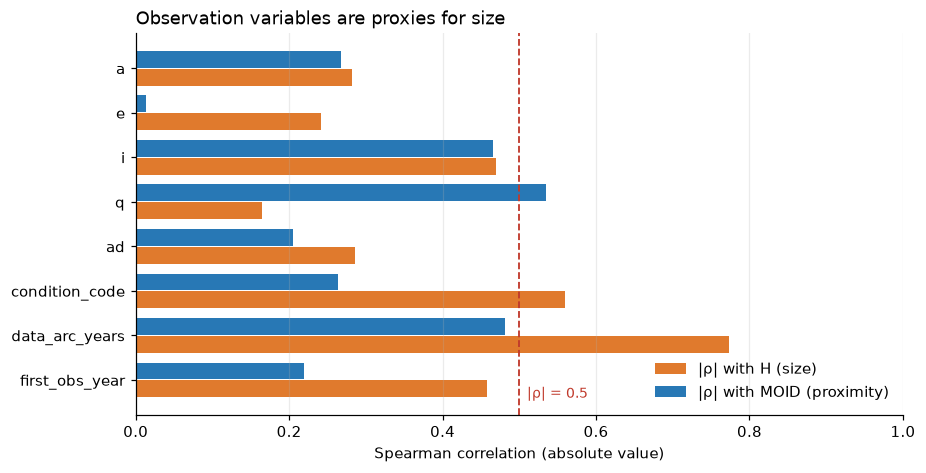

,H,moid_au
a,-0.280,0.270
e,-0.240,-0.010
i,-0.470,0.470
q,-0.160,0.540
ad,-0.290,0.200
condition_code,0.560,-0.260
data_arc_years,-0.770,0.480
first_obs_year,0.460,-0.220


In [3]:
ORBITAL_NUM = ["a", "e", "i", "q", "ad"]
ORBITAL_CAT = ["class"]
OBSERVATION_NUM = ["condition_code", "data_arc_years", "first_obs_year"]

candidates = ORBITAL_NUM + OBSERVATION_NUM
corr = asteroids[candidates + ["H", "moid_au"]].corr(method="spearman").loc[candidates, ["H", "moid_au"]]

fig, ax = plt.subplots(figsize=(9, 4.5))
y = np.arange(len(candidates))
ax.barh(y + 0.2, corr["H"].abs(), height=0.38, color=ORANGE, label="|ρ| with H (size)")
ax.barh(y - 0.2, corr["moid_au"].abs(), height=0.38, color=BLUE, label="|ρ| with MOID (proximity)")
ax.set_yticks(y, candidates)
ax.invert_yaxis()
ax.axvline(0.5, color=RED, ls="--", lw=1.2)
ax.text(0.51, len(candidates) - 0.6, "|ρ| = 0.5", color=RED, fontsize=9, bbox=LABEL_BOX)
ax.set_xlim(0, 1)
ax.set_xlabel("Spearman correlation (absolute value)")
ax.set_title("Observation variables are proxies for size", loc="left")
ax.legend(frameon=False, loc="lower right")
ax.grid(axis="y", visible=False)
save(fig, "size_proximity_proxies")
plt.show()

corr.round(2).to_csv(REPORT_DIR / "proxy_correlations.csv")
corr.round(2)

**Reading:**

- `data_arc_years` (how long the object has been observed) has a correlation of **−0.77** with H. Large objects are brighter, so they are discovered earlier and tracked longer. This variable therefore "knows" the size.
- `condition_code` (orbit uncertainty, 0 to 9) and `first_obs_year` (discovery year) follow the same logic, with a correlation of about 0.5.
- Orbital elements remain moderately correlated with the MOID (q: 0.54). This is expected and legitimate: the orbit physically determines the proximity to Earth. It is not a copy of the target.

**Decision:** two feature sets will be compared in step 5.

- **Orbit** (reference): `a, e, i, q, ad, class`. No leakage, no proxy.
- **Orbit + observation** (variant): adds `condition_code, data_arc_years, first_obs_year`. These variables are available at decision time, but part of their performance will come from size, learned indirectly. This must be stated clearly.

## 3. Dataset A: train / test split for classification

The split is done **first**, before any mean, median or standard deviation is computed. It is **stratified** to keep the same proportion of PHAs (6.2%) on both sides.

In [4]:
FEATURES_ORBIT = ORBITAL_NUM + ORBITAL_CAT
FEATURES_ORBIT_OBS = ORBITAL_NUM + OBSERVATION_NUM + ORBITAL_CAT
LEAKY_FEATURES = ["H", "moid_au"]   # leakage audit only, never used by the model
TARGET = "pha"

keep = ["pdes", TARGET] + ORBITAL_NUM + OBSERVATION_NUM + ORBITAL_CAT + LEAKY_FEATURES
data_A = asteroids[keep].copy()

train_A, test_A = train_test_split(
    data_A, test_size=TEST_SIZE, stratify=data_A[TARGET], random_state=RANDOM_STATE)

split_check = pd.DataFrame({
    "rows": [len(data_A), len(train_A), len(test_A)],
    "PHA": [data_A[TARGET].sum(), train_A[TARGET].sum(), test_A[TARGET].sum()],
    "% PHA": [data_A[TARGET].mean() * 100, train_A[TARGET].mean() * 100, test_A[TARGET].mean() * 100],
}, index=["Catalogue", "Train (80%)", "Test (20%)"])
split_check.to_csv(REPORT_DIR / "classification_split.csv")
split_check

,rows,PHA,% PHA
Catalogue,41281,2539,6.151
Train (80%),33024,2031,6.150
Test (20%),8257,508,6.152


## 4. The preprocessing pipeline

- **Numeric variables**: median imputation, then standardization. Trees do not need it, but clustering and linear models do.
- **Highly skewed variables** (`a`, `ad`, `data_arc_years`): log transform (`log1p`, which handles the zeros of `data_arc_years`) before standardization. A few objects have a semi-major axis of several tens of AU; without the log, they would squash the scale of all the others.
- **Categorical variable** (`class`): one-hot encoding. `handle_unknown="ignore"` avoids an error if a family absent from the training set appears in the test set.

The preprocessor is **defined** here but **never fitted on the whole dataset**. It is placed in a `Pipeline` together with the model, which guarantees that `fit` only sees the training data.

In [5]:
SKEWED = ["a", "ad", "data_arc_years"]   # strictly positive, very spread out

def make_preprocessor(numeric: list[str], categorical: list[str]) -> ColumnTransformer:
    skewed = [c for c in numeric if c in SKEWED]
    regular = [c for c in numeric if c not in SKEWED]
    transformers = []
    if regular:
        transformers.append(("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
        ]), regular))
    if skewed:
        transformers.append(("num_log", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
            ("scaler", StandardScaler()),
        ]), skewed))
    if categorical:
        transformers.append(("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical))
    return ColumnTransformer(transformers, verbose_feature_names_out=False)

preprocessor_orbit = make_preprocessor(ORBITAL_NUM, ORBITAL_CAT)
preprocessor_orbit_obs = make_preprocessor(ORBITAL_NUM + OBSERVATION_NUM, ORBITAL_CAT)
preprocessor_orbit

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('num_log', ...), ...]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature_name}__{transformer_name}""``. See :meth:`str.format` method from the standard library for more info... versionadded:: 1.0.. versionchanged:: 1.6 `verbose_feature_names_out` can be a callable or a string to be formatted.",False
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transfo

### Proof that the test set was not used for fitting

We fit the preprocessor **on the training set only**, then apply it to the test set. After standardization, the training set has exactly a mean of 0 and a standard deviation of 1. The test set deviates slightly: its statistics were not used. Had the scaler been fitted before the split, both would be identical.

In [6]:
demo = make_preprocessor(ORBITAL_NUM, ORBITAL_CAT).fit(train_A[FEATURES_ORBIT])
Xtr = pd.DataFrame(demo.transform(train_A[FEATURES_ORBIT]), columns=demo.get_feature_names_out())
Xte = pd.DataFrame(demo.transform(test_A[FEATURES_ORBIT]), columns=demo.get_feature_names_out())

proof = pd.DataFrame({
    "train mean": Xtr[ORBITAL_NUM].mean(),
    "train std": Xtr[ORBITAL_NUM].std(ddof=0),
    "test mean": Xte[ORBITAL_NUM].mean(),
    "test std": Xte[ORBITAL_NUM].std(ddof=0),
})
proof.to_csv(REPORT_DIR / "scaler_train_only_proof.csv")
print("Output features:", list(demo.get_feature_names_out()))
proof.round(4)

Output features: ['e', 'i', 'q', 'a', 'ad', 'class_AMO', 'class_APO', 'class_ATE', 'class_IEO']


,train mean,train std,test mean,test std
a,0.000,1.000,-0.009,0.973
e,0.000,1.000,0.015,1.013
i,-0.000,1.000,0.019,0.992
q,-0.000,1.000,-0.030,1.019
ad,-0.000,1.000,-0.003,0.986


## 5. Leakage audit

We compare three feature sets with the **same model** (Random Forest, `class_weight="balanced"`) and the **same 5-fold stratified cross-validation**, computed **on the training set only**: the test set stays untouched for step 5.

The preprocessor sits inside the `Pipeline`, so it is refitted in each fold on that fold's 4/5 training portion.

The main metric is the **PR-AUC** (area under the precision/recall curve). A random model scores the PHA proportion, i.e. **0.06**.

In [7]:
def audit_model(numeric, categorical):
    return Pipeline([
        ("prep", make_preprocessor(numeric, categorical)),
        ("model", RandomForestClassifier(n_estimators=200, min_samples_leaf=5,
                                         class_weight="balanced", n_jobs=-1,
                                         random_state=RANDOM_STATE)),
    ])

feature_sets = {
    "Forbidden: H + MOID": (LEAKY_FEATURES, []),
    "Orbit": (ORBITAL_NUM, ORBITAL_CAT),
    "Orbit + observation": (ORBITAL_NUM + OBSERVATION_NUM, ORBITAL_CAT),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

rows = []
for name, (num, cat) in feature_sets.items():
    scores = cross_validate(audit_model(num, cat), train_A[num + cat], train_A[TARGET], cv=cv,
                            scoring={"recall": "recall", "precision": "precision",
                                     "F1": "f1", "PR-AUC": "average_precision"})
    rows.append({"feature set": name,
                 **{m: scores[f"test_{m}"].mean() for m in ["recall", "precision", "F1", "PR-AUC"]}})

audit = pd.DataFrame(rows).set_index("feature set")
audit.to_csv(REPORT_DIR / "leakage_audit.csv")
audit.round(3)

,recall,precision,F1,PR-AUC
feature set,,,,
Forbidden: H + MOID,0.992,0.948,0.970,0.998
Orbit,0.409,0.152,0.222,0.147
Orbit + observation,0.850,0.329,0.475,0.475


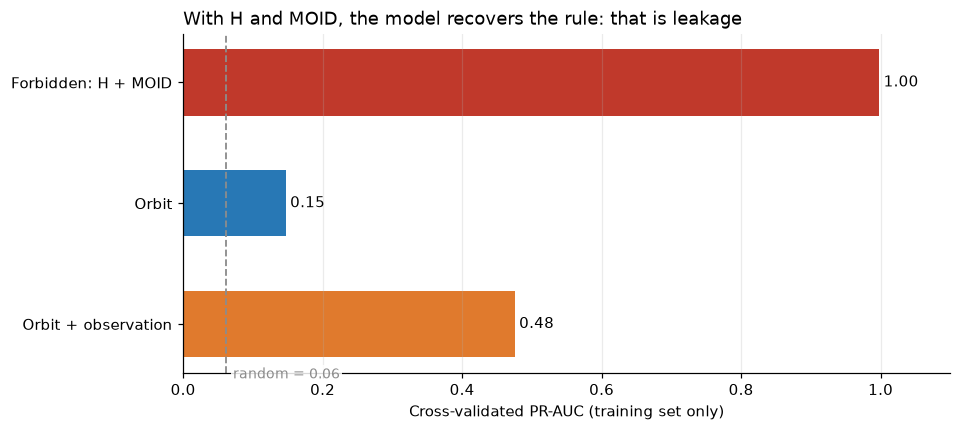

In [8]:
chance = train_A[TARGET].mean()
fig, ax = plt.subplots(figsize=(9, 4))
colors = [RED, BLUE, ORANGE]
bars = ax.barh(audit.index[::-1], audit["PR-AUC"][::-1], color=colors[::-1], height=0.55)
ax.bar_label(bars, labels=[f"{v:.2f}" for v in audit["PR-AUC"][::-1]], padding=3)
ax.axvline(chance, color=GREY, ls="--", lw=1.2)
ax.text(chance + 0.01, -0.45, f"random = {chance:.2f}", color=GREY, fontsize=9, bbox=LABEL_BOX)
ax.set_xlim(0, 1.1)
ax.set_xlabel("Cross-validated PR-AUC (training set only)")
ax.set_title("With H and MOID, the model recovers the rule: that is leakage", loc="left")
ax.grid(axis="y", visible=False)
save(fig, "leakage_audit_pr_auc")
plt.show()

**Reading:**

- **H + MOID**: PR-AUC close to 1. The model recovers the official rule. It is a perfect score that proves nothing, which is exactly the trap avoided.
- **Orbit only**: the signal is real (clearly above random) but modest. This is the honest answer to the question "can a dangerous object be spotted from its orbit alone?". The orbit tells whether the object *can* pass close, not whether it is *large enough*.
- **Orbit + observation**: much better, but part of the gain comes from size learned indirectly through `data_arc_years` (section 2).

**Implication for step 5:** the "orbit" model is the leakage-free reference, and the "orbit + observation" model is presented as a variant, with its limitation. The decision threshold will then be lowered to reach the maximum recall required by the PDCO, while measuring the precision lost.

## 6. Dataset B: diameter regression (preparation for step 4)

We keep only the objects whose diameter is **actually measured**. Estimated diameters are the formula applied to H: using them as a target would give a meaningless R² ≈ 1.

- **Target**: log10 of the diameter in km. Diameters range from a few meters to tens of km; the log makes relative errors comparable across the whole range.
- **Features**: H (allowed here, since the target is no longer `pha`) + orbital elements + family.
- **Excluded: albedo.** With H and the albedo, the physical formula gives the diameter almost exactly. Above all, the albedo is missing for 97% of the catalogue: a model that relies on it could not be applied to the very objects whose size we want to estimate.

In [9]:
measured = asteroids[~asteroids["diameter_is_estimated"]].dropna(subset=["H", "diameter_km"]).copy()
with_albedo = measured.dropna(subset=["albedo"])
formula = 1329 / np.sqrt(with_albedo["albedo"]) * 10 ** (-with_albedo["H"] / 5)
ratio = formula / with_albedo["diameter_km"]
print(f"Objects with a measured diameter: {fmt(len(measured))}")
print(f"With the real albedo, the formula gives the diameter within ±{(ratio - 1).abs().median():.1%} (median) "
      f"→ the albedo would be leakage.")

FEATURES_DIAMETER_NUM = ["H"] + ORBITAL_NUM
FEATURES_DIAMETER_CAT = ORBITAL_CAT
TARGET_DIAMETER = "log10_diameter_km"

data_B = measured[["pdes", "diameter_km"] + FEATURES_DIAMETER_NUM + FEATURES_DIAMETER_CAT].copy()
data_B[TARGET_DIAMETER] = np.log10(data_B["diameter_km"])

# Stratify on target quintiles to keep the same size range on both sides
size_bins = pd.qcut(data_B[TARGET_DIAMETER], q=5, labels=False)
train_B, test_B = train_test_split(data_B, test_size=TEST_SIZE, stratify=size_bins,
                                   random_state=RANDOM_STATE)
print(f"Train: {fmt(len(train_B))} | Test: {fmt(len(test_B))}")

Objects with a measured diameter: 1,244
With the real albedo, the formula gives the diameter within ±4.5% (median) → the albedo would be leakage.
Train: 995 | Test: 249


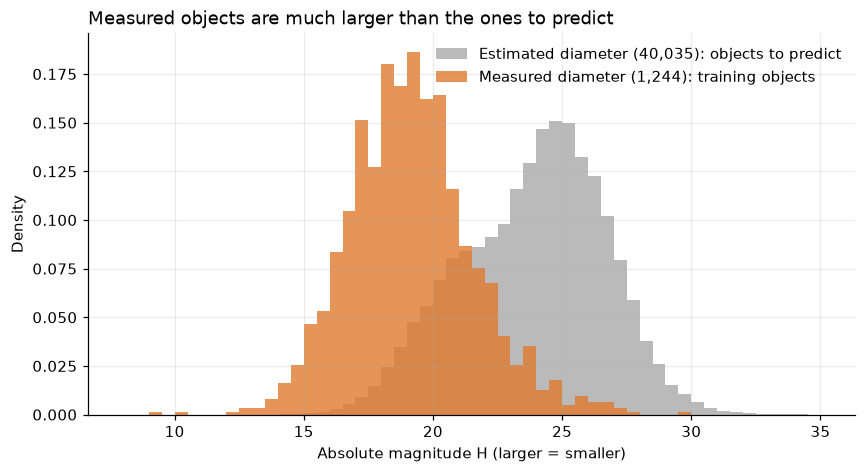

Median H: measured 19.1 | estimated 24.1
Objects with H > 24 (smaller than ~50 m): 3.1% of measured objects (38 objects), vs 51.7% of the objects to predict


In [10]:
estimated = asteroids[asteroids["diameter_is_estimated"]]
fig, ax = plt.subplots(figsize=(9, 4.5))
bins = np.linspace(8, 35, 55)
ax.hist(estimated["H"], bins=bins, density=True, color=GREY, alpha=0.6,
        label=f"Estimated diameter ({fmt(len(estimated))}): objects to predict")
ax.hist(measured["H"], bins=bins, density=True, color=ORANGE, alpha=0.8,
        label=f"Measured diameter ({fmt(len(measured))}): training objects")
ax.set_xlabel("Absolute magnitude H (larger = smaller)")
ax.set_ylabel("Density")
ax.set_title("Measured objects are much larger than the ones to predict", loc="left")
ax.legend(frameon=False)
save(fig, "diameter_population_shift")
plt.show()

print(f"Median H: measured {measured['H'].median():.1f} | estimated {estimated['H'].median():.1f}")
print(f"Objects with H > 24 (smaller than ~50 m): {(measured['H'] > 24).mean():.1%} of measured objects "
      f"({fmt((measured['H'] > 24).sum())} objects), vs {(estimated['H'] > 24).mean():.1%} of the objects to predict")

**Limitation to report:** the step 4 model will learn on mostly large objects (median H ≈ 19) and be applied to mostly small objects (median H ≈ 24). It has very few examples in the small-object range, where half of the catalogue lies. In step 4, the error will be assessed by H bin and out-of-domain objects will be flagged.

## 7. Saving for steps 4 and 5

In [11]:
train_A.to_csv(PROCESSED_DIR / "classification_train.csv", index=False)
test_A.to_csv(PROCESSED_DIR / "classification_test.csv", index=False)
train_B.to_csv(PROCESSED_DIR / "diameter_train.csv", index=False)
test_B.to_csv(PROCESSED_DIR / "diameter_test.csv", index=False)

# UNFITTED preprocessors: they will be fitted inside each model's Pipeline
joblib.dump(make_preprocessor(ORBITAL_NUM, ORBITAL_CAT), PROCESSED_DIR / "preprocessor_orbit.joblib")
joblib.dump(make_preprocessor(ORBITAL_NUM + OBSERVATION_NUM, ORBITAL_CAT), PROCESSED_DIR / "preprocessor_orbit_obs.joblib")
joblib.dump(make_preprocessor(FEATURES_DIAMETER_NUM, FEATURES_DIAMETER_CAT), PROCESSED_DIR / "preprocessor_diameter.joblib")

config = {
    "random_state": RANDOM_STATE,
    "test_size": TEST_SIZE,
    "classification": {
        "target": TARGET,
        "features_orbit": {"numeric": ORBITAL_NUM, "categorical": ORBITAL_CAT},
        "features_orbit_obs": {"numeric": ORBITAL_NUM + OBSERVATION_NUM, "categorical": ORBITAL_CAT},
        "forbidden": ["H", "moid_au", "moid_km", "moid_lunar_distances", "diameter_km",
                      "diameter_m", "size_category", "albedo"],
    },
    "diameter_regression": {
        "target": TARGET_DIAMETER,
        "rows": "diameter_is_estimated == False",
        "features": {"numeric": FEATURES_DIAMETER_NUM, "categorical": FEATURES_DIAMETER_CAT},
        "forbidden": ["albedo", "diameter_m", "size_category"],
    },
}
(REPORT_DIR / "preprocessing_config.json").write_text(json.dumps(config, indent=2), encoding="utf-8")

print("Data:", sorted(p.name for p in PROCESSED_DIR.iterdir()))
print("Reports:", sorted(p.name for p in REPORT_DIR.iterdir()))

Data: ['classification_test.csv', 'classification_train.csv', 'diameter_test.csv', 'diameter_train.csv', 'preprocessor_diameter.joblib', 'preprocessor_orbit.joblib', 'preprocessor_orbit_obs.joblib']
Reports: ['classification_split.csv', 'diameter_population_shift.png', 'feature_inventory.csv', 'leakage_audit.csv', 'leakage_audit_pr_auc.png', 'preprocessing_config.json', 'proxy_correlations.csv', 'scaler_train_only_proof.csv', 'size_proximity_proxies.png']


## Summary

| Anti-leakage rule | Implementation |
|---|---|
| No variable that defines the target | MOID, H and every column derived from H excluded from dataset A (inventory, section 1) |
| No undeclared hidden proxy | Correlations with H and MOID measured; observation variables isolated in a variant (section 2) |
| Split before any computation | Stratified `train_test_split` first (sections 3 and 6) |
| Preprocessor fitted on the training set only | `ColumnTransformer` inside a `Pipeline`, refitted in each cross-validation fold (sections 4 and 5) |
| Quantified proof | Train vs test mean/std (section 4) and H + MOID vs orbit audit (section 5) |
| Non-circular regression target | Measured diameters only, albedo excluded (section 6) |

The next steps load everything from `data/processed/03_preprocessing/` and `reports/03_preprocessing/preprocessing_config.json`, so this notebook must be run before notebooks 04 and 05.